ชื่อ-สกุล / รหัส / หน้าที่สมาชิกทุกคน: **กรอกก่อนส่ง** | Section ___ | กลุ่ม ___

# เลือกพื้นที่เก็บตัวอย่างข้าวด้วยประวัติ Mycotoxin และ NASA POWER
## CS240/245 Term Project — ทำครบใน Google Colab notebook เดียว

**วิธีใช้:** เปิดไฟล์นี้ใน Colab → Runtime → Run all → อัปโหลด **Dashboard (2) (1).xlsx เพียงไฟล์เดียว** ตอนระบบถาม รอเรียก NASA API 22 จุด แล้ว notebook จะทำขั้นตอนต่อไปเอง ใช้ CPU ได้

ลำดับ: Problem Framing → Data Collection (Excel ข้าว + NASA API → สร้าง NASA_POWER.xlsx) → Data Preparation → EDA → เปรียบเทียบ Classification 3 โมเดล → Test → Demo → Interpretation

ไม่ต้องสร้าง NASA_POWER.xlsx ล่วงหน้า ไม่ต้องเปิด notebook อื่น ไฟล์ Excel อากาศเป็นผลลัพธ์ระหว่างขั้นตอนสำหรับเปิดตรวจและนำมา merge ใน notebook นี้

### Problem Framing
ใช้พื้นที่ ประวัติผลตรวจเก่า และอากาศก่อนวันทำนาย เพื่อคาดการณ์ Positive/Negative ของตัวอย่างที่จะเก็บใหม่ ณ พื้นที่นั้น หน่วยข้อมูลคือ sample ไม่ใช่ทั้งจังหวัด Output ยังเป็น have risk/no risk ไม่แบ่ง low/medium/high

**Scenario:** วันเก็บสุ่มภายในเดือน/ปีเดิม, วันทราบผลสมมติ +7 วัน, พิกัดตัวแทนสมมติ; NASA weather เป็นข้อมูลจริง ณ จุด/เวลาที่ร้องขอ แต่ยังไม่ใช่ weather ของ sample จริงที่ยืนยันแล้ว คะแนนโมเดลไม่ใช่หลักฐานความแม่นยำภาคสนาม

ใช้ประวัติปี 2021 คงที่ทำนายตัวอย่างปี 2022 ด้วยโค้ดระดับ CS240: pandas cleansing/groupby/merge, get_dummies, fillna, StandardScaler, fit/predict ไม่มี Pipeline/ColumnTransformer หรือระบบคำนวณประวัติทุก fold

อิงรูปแบบจาก 05_3_Practice_DataCleansing.ipynb, MachineLearning_Supervised-Classification_Example-1.ipynb และ CS240_Lab_Practice_04_Iris_Comprehensive_Exam.ipynb


In [1]:
%pip -q install openpyxl

# ===== นำเข้า library ที่ใช้ทั้ง notebook =====
import pandas as pd                 # จัดการตาราง
import numpy as np                  # คำนวณตัวเลข / สุ่ม
import matplotlib.pyplot as plt     # วาดกราฟ
from IPython.display import display # แสดงตารางสวย ๆ
import requests                     # เรียก NASA POWER API

# เช็คว่ารันบน Google Colab หรือไม่ (ใช้ตอนอัปโหลด/ดาวน์โหลดไฟล์)
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

Note: you may need to restart the kernel to use updated packages.


## 1. Data Collection
### 1.1 อ่าน Excel ข้าว
แหล่งข้อมูล: Dashboard (2) (1).xlsx, sheet Results จากไฟล์ที่กลุ่มได้รับ ต้องเติมหน่วยงานเจ้าของข้อมูล วิธีเก็บ หน่วยสาร และนิยาม Positive ที่ยืนยันแล้วในรายงาน

ข้อมูลมี qualitative เช่นจังหวัด/ชนิดข้าว/ผลตรวจ และ quantitative เช่นค่าสาร ส่วน NASA จะเก็บในหัวข้อถัดไป


In [2]:
# ===== 1.1 อ่าน Excel ผลตรวจข้าว =====
if IN_COLAB:
    files.upload()  # อัปโหลด Dashboard (2) (1).xlsx เพียงไฟล์เดียว

raw = pd.read_excel('Dashboard (2) (1).xlsx', sheet_name='Results')

# คอลัมน์ที่ 8 เป็นต้นไปคือค่าสาร mycotoxin แต่ละชนิด
lab_columns = list(raw.columns[7:])

print('Original rice Excel:', raw.shape)
display(raw.head())

Original rice Excel: (507, 46)


,Timestamp,Sample ID,Type,Sub-type,Location,Date of collection,Result (positive/negative),15-Acetyl_DON,3-Acetyl-DON,Aflatoxin B1,Aflatoxin B2,Aflatoxin G1,Aflatoxin G2,Alternariol,Alternariol monomethyl ether,Beauvericin,Citrinin,Cyclopiazonic acid,Diacetoxyscirpenol,Deoxynivalenol,Emodin,Enniatin A,Enniatin A1,Enniatin B,Enniatin B1,Fumonisin B1,Fumonisin B2,Fusaric acid,HT-2 toxin,Moniliformin,Mycophenolic acid,Neosolaniol,Nivalenol,Ochratoxin A,Ochratoxin B,Patulin,Paxiline,Penitrem A,Sterigmatocystin,T-2 toxin,Tentoxin,Tenuazonic acid,Trimethoprim,Tryptophol,Zearalenone,Deoxynivalenol-3-glucoside
0,NaN,13052026_Sample1_Rice_177.d,Food,White rice,Surin,December 2021,Negative,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,13052026_Sample2_Rice_181.d,Food,White rice,Surin,December 2021,Negative,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,13052026_Sample3_Rice_DLPR2.d,Food,Brown rice,Lampang,2022,Positive,NaN,NaN,NaN,NaN,NaN,NaN,0.626628,NaN,0.397749,NaN,NaN,NaN,NaN,0.139963,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.584994,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.316038,13.104901,NaN
3,NaN,13052026_Sample4_Rice_178.d,Food,White rice,Surin,December 2021,Negative,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,13052026_Sample5_Rice_176.d,Food,White rice,Surin,December 2021,Positive,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.553905,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.778009,NaN,NaN


### 1.2 ตารางจังหวัดและจุดตัวแทน
ตารางนี้เป็นสมมติฐานของ scenario เท่านั้น หากได้พิกัดแปลงจริงต้องเปลี่ยนตารางก่อนดึงข้อมูลใหม่


In [3]:
# ===== 1.2 พิกัดตัวแทนของแต่ละจังหวัด (สมมติ) =====
# (ชื่อจังหวัด, latitude, longitude) ใช้ส่งให้ NASA API
locations = pd.DataFrame([
    ('Amnat Charoen',    15.85, 104.63),
    ('Bangkok',          13.75, 100.5),
    ('Chaiyaphum',       15.81, 102.03),
    ('Chiang Mai',       18.79, 98.99),
    ('Chiang Rai',       19.91, 99.83),
    ('Kalasin',          16.43, 103.51),
    ('Lampang',          18.29, 99.49),
    ('Mahasarakham',     16.18, 103.3),
    ('Mukdahan',         16.54, 104.72),
    ('Nakhon Pathom',    13.82, 100.06),
    ('Narathiwat',       6.43,  101.82),
    ('Pathum Thani',     14.02, 100.53),
    ('Phayao',           19.17, 99.9),
    ('Phichit',          16.44, 100.35),
    ('Roi Et',           16.05, 103.65),
    ('Si Sa Ket',        15.12, 104.32),
    ('Songkhla',         7.2,   100.6),
    ('Suphan Buri',      14.47, 100.12),
    ('Surin',            14.88, 103.49),
    ('Ubon Ratchathani', 15.24, 104.85),
    ('Yala',             6.54,  101.28),
    ('Yasothon',         15.79, 104.15),
], columns=['Location', 'Latitude', 'Longitude'])

# ระบุไว้ว่าพิกัดเป็นค่าตัวแทน ไม่ใช่พิกัดแปลงจริง
locations['Coordinates_are_proxy'] = True
display(locations)

,Location,Latitude,Longitude,Coordinates_are_proxy
0,Amnat Charoen,15.85,104.63,True
1,Bangkok,13.75,100.50,True
2,Chaiyaphum,15.81,102.03,True
3,Chiang Mai,18.79,98.99,True
4,Chiang Rai,19.91,99.83,True
5,Kalasin,16.43,103.51,True
6,Lampang,18.29,99.49,True
7,Mahasarakham,16.18,103.30,True
8,Mukdahan,16.54,104.72,True
9,Nakhon Pathom,13.82,100.06,True


### 1.3 เรียก API ทีละจังหวัด
ดึงอุณหภูมิ T2M (°C), ความชื้น RH2M (%), ฝน PRECTOTCORR (mm/day) ตั้งแต่ 1 พ.ย. 2021 ถึง 31 ธ.ค. 2022 แบบ LST

ใช้ `raise_for_status()` เพื่อหยุดถ้า API มีปัญหา ไม่แทนข้อมูลที่ดึงไม่ได้ด้วยค่าปลอม NASA มีความละเอียดแบบกริด ไม่ใช่เครื่องวัดในแต่ละแปลง


เอกสาร: [NASA POWER Daily API](https://power.larc.nasa.gov/docs/services/api/temporal/daily/) / [NASA API tutorial](https://power.larc.nasa.gov/docs/tutorials/service-data-request/api/)

In [4]:
# ===== 1.3 ดึงอากาศรายวันจาก NASA POWER ทีละจังหวัด =====
# T2M = อุณหภูมิ (°C), RH2M = ความชื้นสัมพัทธ์ (%), PRECTOTCORR = ฝน (mm/day)
daily_tables = []  # เก็บตารางอากาศของแต่ละจังหวัด
sources = []       # เก็บ URL ที่เรียก ไว้อ้างอิงแหล่งข้อมูล

for row in locations.itertuples():
    params = {
        'parameters': 'T2M,RH2M,PRECTOTCORR',
        'community': 'AG',
        'latitude': row.Latitude,
        'longitude': row.Longitude,
        'start': '20211101',
        'end': '20221231',
        'format': 'JSON',
        'time-standard': 'LST',  # ใช้เวลาท้องถิ่น
    }
    response = requests.get('https://power.larc.nasa.gov/api/temporal/daily/point',
                            params=params, timeout=60)
    response.raise_for_status()  # ถ้า API error ให้หยุดทันที ไม่ใช้ข้อมูลปลอมแทน
    data = response.json()

    # ตรวจหน่วยให้ตรงกับที่คาดไว้
    for name, unit in {'T2M': 'C', 'RH2M': '%', 'PRECTOTCORR': 'mm/day'}.items():
        assert data['parameters'][name]['units'] == unit, 'NASA units changed'

    # แปลง JSON เป็นตาราง: 1 แถว = 1 วัน
    weather = pd.DataFrame(data['properties']['parameter'])[['T2M', 'RH2M', 'PRECTOTCORR']]
    weather = weather.replace(data['header']['fill_value'], np.nan)  # ค่าว่างของ NASA (-999) → NaN
    weather.index = pd.to_datetime(weather.index, format='%Y%m%d')
    weather.index.name = 'Date'
    weather = weather.reset_index()
    weather['Location'] = row.Location

    daily_tables.append(weather)
    sources.append({'Location': row.Location, 'URL': response.url, 'Source': 'NASA POWER',
                    'Time_standard': 'LST', 'Coordinates_are_proxy': True})
    print('Downloaded:', row.Location)

# รวมทุกจังหวัดเป็นตารางเดียว
daily = pd.concat(daily_tables, ignore_index=True)

# ตรวจความถูกต้องเบื้องต้น
assert not daily.duplicated(['Location', 'Date']).any()  # ไม่มีวันซ้ำในจังหวัดเดียวกัน
assert daily['RH2M'].dropna().between(0, 100).all()      # ความชื้นอยู่ในช่วง 0–100%
assert daily['PRECTOTCORR'].dropna().ge(0).all()         # ฝนไม่ติดลบ
display(daily.head())

Downloaded: Amnat Charoen
Downloaded: Bangkok
Downloaded: Chaiyaphum
Downloaded: Chiang Mai
Downloaded: Chiang Rai
Downloaded: Kalasin
Downloaded: Lampang
Downloaded: Mahasarakham
Downloaded: Mukdahan
Downloaded: Nakhon Pathom
Downloaded: Narathiwat
Downloaded: Pathum Thani
Downloaded: Phayao
Downloaded: Phichit
Downloaded: Roi Et
Downloaded: Si Sa Ket
Downloaded: Songkhla
Downloaded: Suphan Buri
Downloaded: Surin
Downloaded: Ubon Ratchathani
Downloaded: Yala
Downloaded: Yasothon


,Date,T2M,RH2M,PRECTOTCORR,Location
0,2021-11-01,25.97,88.62,0.17,Amnat Charoen
1,2021-11-02,26.03,86.08,0.17,Amnat Charoen
2,2021-11-03,25.65,86.79,0.04,Amnat Charoen
3,2021-11-04,26.00,85.47,0.00,Amnat Charoen
4,2021-11-05,27.05,82.49,0.00,Amnat Charoen


### 1.4 สรุปอากาศ 30 วันก่อนวันที่จะทำนาย
สำหรับวัน T ใช้ T−30 ถึง T−1 เท่านั้น `.rolling(30)` สรุป 30 วัน และ `.shift(1)` เลื่อนให้ไม่รวมอากาศวัน T

Reindex ให้มีทุกวันก่อนคำนวณ ถ้าข้อมูลขาดจะไม่สรุปหน้าต่างนั้น ไม่มีการเติมฝนที่หายเป็น 0 ชีต Weather_30d มีหนึ่งแถวต่อ Location + Date และพร้อมใช้ `merge()`


In [5]:
# ===== 1.4 สรุปอากาศ 30 วันก่อนหน้า (T-30 ถึง T-1) =====
summary_tables = []

for location, group in daily.groupby('Location'):
    weather = group.set_index('Date').sort_index()
    # ทำให้มีครบทุกวัน ถ้าวันไหนขาดจะเป็น NaN (ไม่เติมเป็น 0)
    weather = weather.reindex(pd.date_range('2021-11-01', '2023-01-01'))

    summary = pd.DataFrame(index=weather.index)
    # rolling(30) = สรุป 30 วัน, shift(1) = ไม่รวมอากาศของวัน T เอง
    summary['Temperature_30d'] = weather['T2M'].rolling(30, min_periods=30).mean().shift(1)
    summary['Humidity_30d']    = weather['RH2M'].rolling(30, min_periods=30).mean().shift(1)
    summary['Rain_30d']        = weather['PRECTOTCORR'].rolling(30, min_periods=30).sum().shift(1)
    summary['Location'] = location
    summary.index.name = 'Date'

    # ตัดวันที่ข้อมูลไม่ครบ 30 วันออก
    summary_tables.append(summary.dropna().reset_index())

weather_30d = pd.concat(summary_tables, ignore_index=True)
assert not weather_30d.duplicated(['Location', 'Date']).any()

# เช็คตัวอย่างว่าฝน 30 วันของ 1 ม.ค. มาจาก 2–31 ธ.ค. จริง
check = daily[(daily['Location'] == 'Bangkok') & daily['Date'].between('2022-12-02', '2022-12-31')]
expected = check['PRECTOTCORR'].sum(min_count=30)
actual = weather_30d.loc[(weather_30d['Location'] == 'Bangkok') & (weather_30d['Date'] == '2023-01-01'),
                         'Rain_30d'].iloc[0]
assert np.isclose(actual, expected)
display(weather_30d.head())

,Date,Temperature_30d,Humidity_30d,Rain_30d,Location
0,2021-12-01,23.335000,84.820000,1.21,Amnat Charoen
1,2021-12-02,23.122667,84.505333,1.04,Amnat Charoen
2,2021-12-03,22.865333,84.354333,0.87,Amnat Charoen
3,2021-12-04,22.589667,84.154333,0.83,Amnat Charoen
4,2021-12-05,22.294667,84.056333,0.83,Amnat Charoen


### 1.5 บันทึก NASA เป็น Excel แล้วอ่านกลับเพื่อใช้ต่อ
สร้าง NASA_POWER.xlsx ใน runtime นี้: Daily = อากาศรายวัน, Weather_30d = อากาศย้อนหลังพร้อม merge, Locations = จุดตัวแทน, Sources = URL ที่ร้องขอ

อ่าน sheet Weather_30d เป็นตัวแปร weather แล้วทำ Data Preparation ต่อได้ทันที ไม่ต้องดาวน์โหลดหรือ upload ไฟล์ระหว่างทาง ถ้า API มีปัญหาให้ตรวจเครือข่าย/บริการแล้วรันส่วน Data Collection ใหม่ ไม่ใช้ข้อมูลปลอมแทน


In [6]:
# ===== 1.5 บันทึกข้อมูลอากาศเป็น NASA_POWER.xlsx =====
with pd.ExcelWriter('NASA_POWER.xlsx', engine='openpyxl') as writer:
    daily.to_excel(writer, sheet_name='Daily', index=False)              # อากาศรายวัน
    weather_30d.to_excel(writer, sheet_name='Weather_30d', index=False)  # สรุป 30 วัน
    locations.to_excel(writer, sheet_name='Locations', index=False)      # พิกัดตัวแทน
    pd.DataFrame(sources).to_excel(writer, sheet_name='Sources', index=False)  # URL ที่เรียก
print('Saved NASA_POWER.xlsx:', len(daily), 'daily rows;', len(weather_30d), '30-day rows')

# อ่านกลับมาใช้ต่อ (แสดงว่าใช้ข้อมูลจากไฟล์ Excel จริง)
weather = pd.read_excel('NASA_POWER.xlsx', sheet_name='Weather_30d')
print('Read Weather_30d back from Excel:', weather.shape)

Saved NASA_POWER.xlsx: 9372 daily rows; 8734 30-day rows
Read Weather_30d back from Excel: (8734, 5)


## 2. Data Preparation
### 2.1 สำรวจและสร้างวันสมมติ
เลือก White rice / Brown rice เฉพาะ 2021–2022 เก็บปีอื่นแยกไว้ตรวจ ไม่แก้ปีโดยเดา ใช้ qualitative (จังหวัด/ผลตรวจ) และ quantitative (ค่าสาร/อากาศ)

สุ่มวันภายในเดือน December ถ้าระบุเดือน หรือภายในปี 2022 ถ้ามีเพียงปี ใช้ seed 42 ไม่ใช้ผลตรวจในการเลือกวัน


In [7]:
# ===== 2.1 เลือกข้อมูลที่ใช้ และสร้างวันเก็บตัวอย่างสมมติ =====
# เลือกเฉพาะข้าวขาว / ข้าวกล้อง
rice = raw[raw['Sub-type'].isin(['White rice', 'Brown rice'])].copy()

# เก็บเฉพาะช่วงเวลาที่รู้ชัด ส่วนปีอื่นแยกไว้ตรวจ (ไม่เดาแก้ปี)
period = rice['Date of collection'].astype(str).str.strip()
valid = period.isin(['2022', 'December 2021', 'December 2022'])
excluded_years = rice[~valid].copy()
rice = rice[valid].reset_index(drop=True)

# ปรับชื่อจังหวัดให้เป็นแบบเดียวกัน
rice['Location'] = (rice['Location'].str.strip().str.title()
                    .replace({'Pha Yao': 'Phayao', 'Amnart Charoen': 'Amnat Charoen'}))
assert rice['Sample ID'].notna().all() and rice['Sample ID'].is_unique

# สุ่มวันเก็บ: ถ้าระบุเดือน ธ.ค. → สุ่มใน ธ.ค., ถ้าระบุแค่ปี 2022 → สุ่มทั้งปี
rng = np.random.default_rng(42)  # seed คงที่ ให้ผลเหมือนเดิมทุกครั้ง
mock_dates = []
for period in rice['Date of collection'].astype(str).str.strip():
    if period == '2022':
        start, days = pd.Timestamp('2022-01-01'), 365
    else:
        start, days = pd.Timestamp(period[-4:] + '-12-01'), 31
    mock_dates.append(start + pd.Timedelta(days=int(rng.integers(days))))

rice['Date'] = mock_dates
rice['Result_available'] = rice['Date'] + pd.Timedelta(days=7)  # สมมติว่าทราบผลหลังเก็บ 7 วัน
rice['Date_is_mock'] = True

# เก็บสำเนาข้อมูลสะอาดไว้เทียบผล cleansing ทีหลัง
reference = rice.copy()

print('Scenario rows:', len(rice), '| excluded years:', len(excluded_years))
display(rice['Result (positive/negative)'].value_counts())

Scenario rows: 440 | excluded years: 6


Result (positive/negative)
Negative    374
Positive     66
Name: count, dtype: int64

### 2.2 สร้าง inconsistent data ตามโจทย์
ทำในสำเนา: ชื่อจังหวัดตัวพิมพ์/ช่องว่าง/alias, วันที่สองรูปแบบ, label ตัวพิมพ์/ช่องว่าง และแถวซ้ำ 5 แถว เก็บ clean reference เพื่อเช็คผล cleansing


In [8]:
# ===== 2.2 สร้างข้อมูลสกปรก (inconsistent data) ตามโจทย์ =====
dirty = rice.copy()

# ชื่อจังหวัด: ตัวพิมพ์ใหญ่/เล็กปนกัน + มีช่องว่างเกิน + ใช้ชื่อเรียกอื่น
dirty['Location'] = dirty['Location'].str.upper() + ' '
dirty.loc[dirty.index % 2 == 0, 'Location'] = dirty.loc[dirty.index % 2 == 0, 'Location'].str.lower()
dirty.loc[rice['Location'] == 'Phayao', 'Location'] = ' Pha Yao '

# วันที่: ใช้สองรูปแบบ (YYYY-MM-DD และ DD/MM/YYYY)
dirty['Date'] = rice['Date'].dt.strftime('%Y-%m-%d')
dirty.loc[dirty.index % 2 == 0, 'Date'] = rice.loc[rice.index % 2 == 0, 'Date'].dt.strftime('%d/%m/%Y')

# ผลตรวจ: ตัวพิมพ์เล็ก + มีช่องว่างหน้า/หลัง
dirty['Result (positive/negative)'] = ' ' + dirty['Result (positive/negative)'].str.lower() + ' '

# เพิ่มแถวซ้ำ 5 แถว
dirty = pd.concat([dirty, dirty.head(5)], ignore_index=True)

dirty.to_excel('Rice_Dirty.xlsx', index=False)
display(dirty[['Location', 'Date', 'Result (positive/negative)']].head())

,Location,Date,Result (positive/negative)
0,surin,03/12/2021,negative
1,SURIN,2021-12-24,negative
2,lampang,27/08/2022,positive
3,SURIN,2021-12-14,negative
4,surin,14/12/2021,positive


### 2.3 Cleansing แบบที่เรียน
ใช้ str.strip/title, replace, to_datetime และ drop_duplicates กำหนดรูปแบบวันที่ชัดเจนเพื่อไม่สลับเดือนกับวัน

เก็บ `<LOD` เป็นสถานะต่างจากช่องว่าง: ทั้งคู่ไม่มีค่าปริมาณแน่นอน จึงไม่ใช้คำนวณค่าเฉลี่ยสาร ไม่ถือว่าเป็น 0 ค่า median ที่เติมตอน ML เป็นค่าทางคณิตศาสตร์ใน feature matrix ไม่ได้แก้ผลแล็บจริง


In [9]:
# ===== 2.3 Cleansing ข้อมูลสกปรก =====
rice = pd.read_excel('Rice_Dirty.xlsx')

# ชื่อจังหวัด: ตัดช่องว่าง → Title Case → แก้ชื่อเรียกอื่น
rice['Location'] = (rice['Location'].str.strip().str.title()
                    .replace({'Pha Yao': 'Phayao', 'Amnart Charoen': 'Amnat Charoen'}))

# ผลตรวจ: ตัดช่องว่าง → Title Case (Positive / Negative)
rice['Result (positive/negative)'] = rice['Result (positive/negative)'].str.strip().str.title()

# วันที่: แยกแปลงตามรูปแบบ เพื่อไม่ให้วันกับเดือนสลับกัน
is_slash = rice['Date'].str.contains('/')
rice['Date'] = pd.to_datetime(rice['Date'].where(~is_slash), format='%Y-%m-%d').fillna(
    pd.to_datetime(rice['Date'].where(is_slash), format='%d/%m/%Y'))

# ลบแถวซ้ำ
rice = rice.drop_duplicates().reset_index(drop=True)

# ตรวจว่า cleansing แล้วได้ข้อมูลตรงกับต้นฉบับ
assert rice['Sample ID'].is_unique, 'Conflicting duplicate IDs: check source'
for column in ['Sample ID', 'Date', 'Location', 'Result (positive/negative)']:
    assert rice[column].tolist() == reference[column].tolist(), column
assert rice['Result (positive/negative)'].isin(['Positive', 'Negative']).all()

# สร้าง target: Positive = 1, Negative = 0
rice['target'] = rice['Result (positive/negative)'].map({'Positive': 1, 'Negative': 0})

# ตารางเปรียบเทียบก่อน/หลัง cleansing
quality = pd.DataFrame({
    'stage': ['dirty', 'clean'],
    'rows': [len(dirty), len(rice)],
    'location_spellings': [dirty['Location'].nunique(), rice['Location'].nunique()],
    'duplicate_IDs': [dirty['Sample ID'].duplicated().sum(), rice['Sample ID'].duplicated().sum()],
})
display(quality)

# ----- แปลงค่าสารเป็นตัวเลข -----
# '<LOD' (ต่ำกว่าค่าที่ตรวจวัดได้) และช่องว่าง จะกลายเป็น NaN ไม่ถือเป็น 0
lab_text = rice[lab_columns].astype('string').apply(lambda column: column.str.strip())
lab_numeric = lab_text.apply(pd.to_numeric, errors='coerce').astype(float)

# ถ้าเจอข้อความแปลก ๆ ที่ไม่ใช่ตัวเลขหรือ '<LOD' ให้หยุดตรวจก่อน
unknown = lab_text.notna() & lab_numeric.isna() & lab_text.ne('<LOD')
assert not unknown.any().any(), 'Unknown lab text: check source before continuing'
display(pd.DataFrame({'missing': lab_text.isna().sum(), 'below_LOD': lab_text.eq('<LOD').sum()}))
rice[lab_columns] = lab_numeric

# หาแถวที่ label ไม่ตรงกับค่าสาร (เช่น Positive แต่ไม่มีสารไหน > 0) ไว้ตรวจเพิ่ม
label_review = rice[rice['target'].ne(lab_numeric.gt(0).any(axis=1).astype(int))]
print('Label vs any numeric > 0 disagreements:', len(label_review))
display(label_review[['Sample ID', 'Location', 'Result (positive/negative)']])
rice.info()

Label vs any numeric > 0 disagreements: 2
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 50 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Timestamp                     0 non-null      float64       
 1   Sample ID                     440 non-null    str           
 2   Type                          440 non-null    str           
 3   Sub-type                      440 non-null    str           
 4   Location                      440 non-null    str           
 5   Date of collection            440 non-null    object        
 6   Result (positive/negative)    440 non-null    str           
 7   15-Acetyl_DON                 0 non-null      float64       
 8   3-Acetyl-DON                  0 non-null      float64       
 9   Aflatoxin B1                  3 non-null      float64       
 10  Aflatoxin B2                  0 non-null      float64       
 11  A

,stage,rows,location_spellings,duplicate_IDs
0,dirty,445,41,5
1,clean,440,22,0


,missing,below_LOD
15-Acetyl_DON,440,0
3-Acetyl-DON,440,0
Aflatoxin B1,276,161
Aflatoxin B2,440,0
Aflatoxin G1,440,0
Aflatoxin G2,440,0
Alternariol,439,0
Alternariol monomethyl ether,438,0
Beauvericin,434,0
Citrinin,440,0


,Sample ID,Location,Result (positive/negative)
9,13052026_Sample10_TINT69.d,Ubon Ratchathani,Negative
18,13052026_Sample45_Rice_2ndLot_18.d,Roi Et,Negative


### 2.4 ประวัติปี 2021 ด้วย groupby
ใช้ผลตรวจปี 2021 ที่ทราบก่อน 8 ม.ค. 2022 เป็นฐานประวัติคงที่ ไม่อัปเดตด้วย target ปี 2022 จึงไม่ต้องเขียนระบบ as-of history ทุก fold

คำนวณค่าเฉลี่ยแต่ละสารแยกกัน + จำนวนตัวอย่างเก่า + positive fraction เก่า จังหวัดไม่มีประวัติจะมี History_count=0 และค่าอื่น missing (ไม่ได้แปลว่าปลอดภัย)

**ข้อจำกัด:** บางจังหวัดไม่มีปี 2021; ประวัติไม่อัปเดตตลอดปี วิธีนี้ง่ายขึ้นแต่ตอบโจทย์ด้วยข้อมูลน้อยกว่าระบบที่อัปเดตผลตรวจต่อเนื่อง


In [10]:
# ===== 2.4 สรุปประวัติปี 2021 ของแต่ละจังหวัด =====
# ประวัติ = ผลตรวจปี 2021 ที่ทราบผลก่อน 8 ม.ค. 2022
history = rice[(rice['Date'].dt.year == 2021) & (rice['Result_available'] < '2022-01-08')].copy()

# ค่าเฉลี่ยของแต่ละสาร (เติม Past_ นำหน้าชื่อคอลัมน์)
lab_history = history.groupby('Location')[lab_columns].mean().add_prefix('Past_')

# จำนวนตัวอย่างเก่า และสัดส่วน Positive เก่า
counts = history.groupby('Location')['target'].agg(History_count='size', History_positive_rate='mean')
history_summary = counts.join(lab_history).reset_index()

# ข้อมูลที่ใช้สร้างโมเดล = ปี 2022 ตั้งแต่ 8 ม.ค. เป็นต้นไป
model_rows = rice[(rice['Date'].dt.year == 2022) & (rice['Date'] >= '2022-01-08')].copy()
excluded_early = rice[(rice['Date'].dt.year == 2022) & (rice['Date'] < '2022-01-08')].copy()

# ตรวจว่าประวัติทราบผลก่อนวันที่จะทำนาย และไม่มีตัวอย่างซ้ำกัน
assert history['Result_available'].max() < model_rows['Date'].min()
assert set(history['Sample ID']).isdisjoint(model_rows['Sample ID'])

print('History rows:', len(history), '| model rows:', len(model_rows),
      '| early January excluded:', len(excluded_early))
display(history_summary[['Location', 'History_count', 'History_positive_rate']])

History rows: 171 | model rows: 268 | early January excluded: 1


,Location,History_count,History_positive_rate
0,Chiang Mai,20,0.350000
1,Chiang Rai,21,0.142857
2,Mahasarakham,10,0.500000
3,Phayao,10,0.100000
4,Roi Et,49,0.122449
5,Si Sa Ket,23,0.173913
6,Surin,19,0.210526
7,Yasothon,19,0.052632


### 2.5 Merge สองตารางด้วย Location และ Date
NASA_POWER.xlsx มีข้อมูลอากาศสรุปแล้ว ใช้ `merge()` ตรง ๆ จากนั้น merge ประวัติจังหวัด ตรวจว่าแถวไม่เพิ่มและอากาศไม่หาย


In [11]:
# ===== 2.5 Merge ข้อมูลข้าว + อากาศ + ประวัติจังหวัด =====
weather_columns = ['Temperature_30d', 'Humidity_30d', 'Rain_30d']
weather['Date'] = pd.to_datetime(weather['Date'])
assert not weather.duplicated(['Location', 'Date']).any()

# merge อากาศด้วย Location + Date
data = model_rows.merge(weather[['Location', 'Date'] + weather_columns],
                        on=['Location', 'Date'], how='left', validate='many_to_one')

# merge ประวัติด้วย Location (จังหวัดที่ไม่มีประวัติ → History_count = 0)
data = data.merge(history_summary, on='Location', how='left', validate='many_to_one')
data['History_count'] = data['History_count'].fillna(0)

# ตรวจว่าจำนวนแถวไม่เพิ่ม และอากาศไม่หาย
assert len(data) == len(model_rows)
assert data[weather_columns].notna().all().all(), 'Missing weather: check NASA Excel'

# กำหนด feature ที่ใช้ทำนาย
numeric_features = (weather_columns
                    + ['History_count', 'History_positive_rate']
                    + ['Past_' + c for c in lab_columns])
features = ['Location'] + numeric_features

# ห้ามใช้ผลตรวจของตัวอย่างเองเป็น input (ป้องกัน data leakage)
assert set(features).isdisjoint(lab_columns + ['target', 'Sample ID']), 'New sample results must not be inputs'

data = data.sort_values(['Date', 'Sample ID']).reset_index(drop=True)
display(data[['Location', 'Date', 'History_count'] + weather_columns + ['target']].head())

,Location,Date,History_count,Temperature_30d,Humidity_30d,Rain_30d,target
0,Ubon Ratchathani,2022-01-08,0.0,23.289333,76.962000,3.70,0
1,Phayao,2022-01-09,10.0,19.402667,79.379667,1.97,1
2,Ubon Ratchathani,2022-01-09,0.0,23.358000,76.223000,3.70,0
3,Chiang Mai,2022-01-12,20.0,18.536667,80.383667,1.34,0
4,Chiang Mai,2022-01-13,20.0,18.611000,80.173000,1.34,0


## 3. EDA / Data Visualization
สัดส่วน Positive เป็นของตัวอย่างที่มี ไม่ใช่ทั้งประชากร เปรียบเทียบจำนวนตัวอย่างก่อนแปลผลรายจังหวัด กราฟ weather มาจากการ join ด้วยวันสมมติจึงไม่ใช่หลักฐานเชิงเหตุและผล


Modeling rows without 2021 history: 178


<ipython-input-12-12d92298a55d>:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig('eda_simple.png', dpi=150); plt.show()


,Temperature_30d,Humidity_30d,Rain_30d,History_count,History_positive_rate,Past_15-Acetyl_DON,Past_3-Acetyl-DON,Past_Aflatoxin B1,Past_Aflatoxin B2,Past_Aflatoxin G1,Past_Aflatoxin G2,Past_Alternariol,Past_Alternariol monomethyl ether,Past_Beauvericin,Past_Citrinin,Past_Cyclopiazonic acid,Past_Diacetoxyscirpenol,Past_Deoxynivalenol,Past_Emodin,Past_Enniatin A,Past_Enniatin A1,Past_Enniatin B,Past_Enniatin B1,Past_Fumonisin B1,Past_Fumonisin B2,Past_Fusaric acid,Past_HT-2 toxin,Past_Moniliformin,Past_Mycophenolic acid,Past_Neosolaniol,Past_Nivalenol,Past_Ochratoxin A,Past_Ochratoxin B,Past_Patulin,Past_Paxiline,Past_Penitrem A,Past_Sterigmatocystin,Past_T-2 toxin,Past_Tentoxin,Past_Tenuazonic acid,Past_Trimethoprim,Past_Tryptophol,Past_Zearalenone,Past_Deoxynivalenol-3-glucoside
count,268.000000,268.000000,268.000000,268.000000,90.000000,0.0,0.0,65.0,0.0,0.0,0.0,0.0,1.000000,0.0,0.0,0.0,1.700000e+01,1.000,0.0,0.0,0.0,0.0,0.0,90.000000,0.0,1.000000,17.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.000000,1.000000,0.0
mean,25.427769,81.364075,187.895224,6.500000,0.301682,NaN,NaN,0.4,NaN,NaN,NaN,NaN,0.027982,NaN,NaN,NaN,4.873963e-01,8.525,NaN,NaN,NaN,NaN,NaN,4.132076,NaN,1.242608,0.370794,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.311885,1.374939,NaN
std,2.315082,8.652188,140.914759,9.464105,0.082779,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.721958e-17,NaN,NaN,NaN,NaN,NaN,NaN,0.532659,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN
min,18.470333,58.971667,1.340000,0.000000,0.100000,NaN,NaN,0.4,NaN,NaN,NaN,NaN,0.027982,NaN,NaN,NaN,4.873963e-01,8.525,NaN,NaN,NaN,NaN,NaN,2.646468,NaN,1.242608,0.370794,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.311885,1.374939,NaN
25%,24.168417,74.458000,54.117500,0.000000,0.210526,NaN,NaN,0.4,NaN,NaN,NaN,NaN,0.027982,NaN,NaN,NaN,4.873963e-01,8.525,NaN,NaN,NaN,NaN,NaN,3.633746,NaN,1.242608,0.370794,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.311885,1.374939,NaN
50%,25.994167,84.661833,163.835000,0.000000,0.350000,NaN,NaN,0.4,NaN,NaN,NaN,NaN,0.027982,NaN,NaN,NaN,4.873963e-01,8.525,NaN,NaN,NaN,NaN,NaN,4.411429,NaN,1.242608,0.370794,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.311885,1.374939,NaN
75%,26.925667,87.957667,291.852500,19.000000,0.350000,NaN,NaN,0.4,NaN,NaN,NaN,NaN,0.027982,NaN,NaN,NaN,4.873963e-01,8.525,NaN,NaN,NaN,NaN,NaN,4.411429,NaN,1.242608,0.370794,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.311885,1.374939,NaN
max,29.974000,93.376333,659.430000,49.000000,0.350000,NaN,NaN,0.4,NaN,NaN,NaN,NaN,0.027982,NaN,NaN,NaN,4.873963e-01,8.525,NaN,NaN,NaN,NaN,NaN,4.845000,NaN,1.242608,0.370794,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.311885,1.374939,NaN


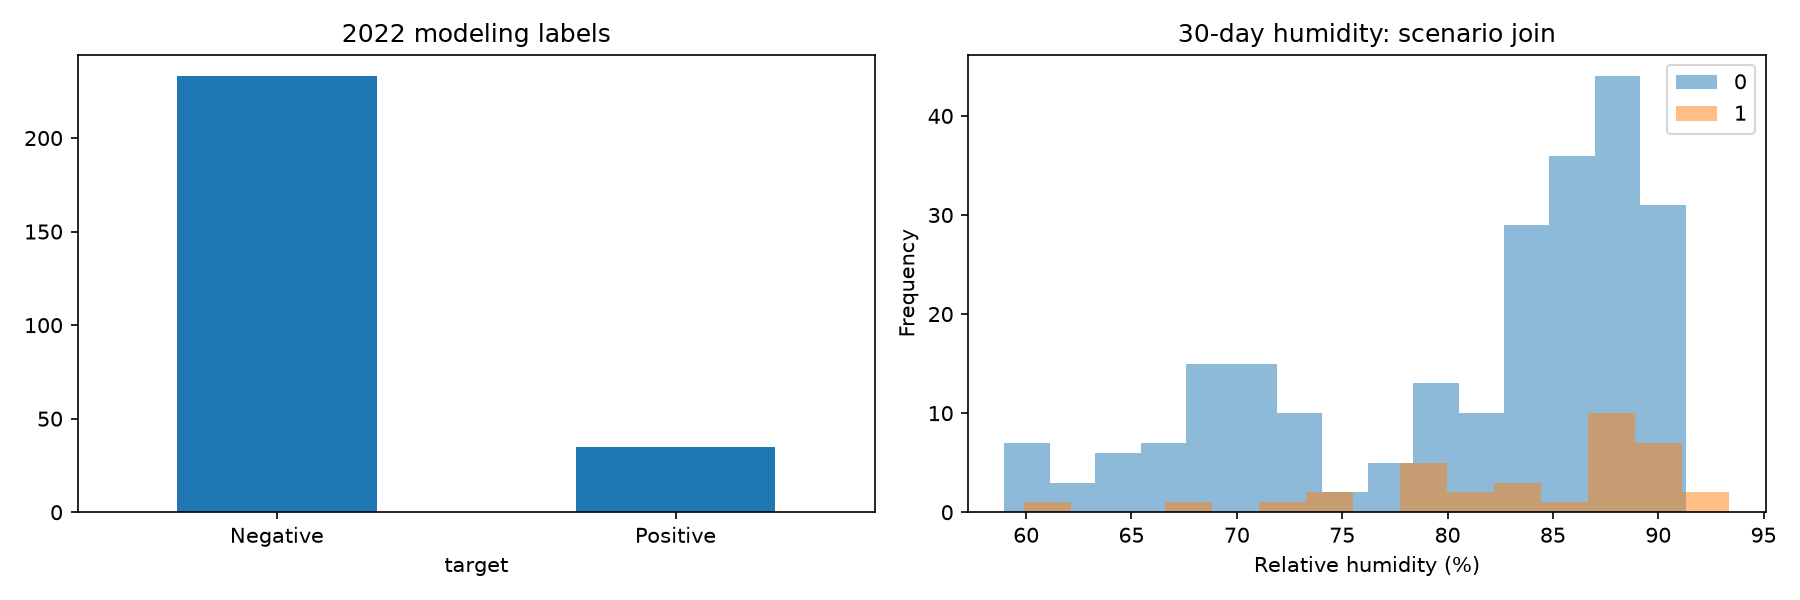

In [12]:
# ===== 3. EDA =====
# สถิติพื้นฐานของ feature ตัวเลข
display(data[numeric_features].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# กราฟซ้าย: จำนวน Negative / Positive
(data['target'].value_counts().sort_index()
 .rename(index={0: 'Negative', 1: 'Positive'})
 .plot.bar(ax=axes[0], rot=0, title='2022 modeling labels'))

# กราฟขวา: การกระจายความชื้น 30 วัน แยกตามผลตรวจ
data.groupby('target')['Humidity_30d'].plot.hist(ax=axes[1], bins=15, alpha=0.5, legend=True)
axes[1].set_title('30-day humidity: scenario join')
axes[1].set_xlabel('Relative humidity (%)')

plt.tight_layout()
plt.savefig('eda_simple.png', dpi=150)
plt.show()

print('Modeling rows without 2021 history:', int(data['History_count'].eq(0).sum()))

## 4. Classification
### 4.1 แบ่ง Train / Validation / Test ตามวันสมมติ
ใช้ 60% / 20% / 20% ของ **วันไม่ซ้ำ** ไม่ใช่จำนวนแถว เลือกโมเดลจาก validation แล้วใช้ test ตรวจครั้งสุดท้าย ไม่เลือกจาก test

ตัดแถวฝึกที่ผลยังไม่ทราบตอนเริ่ม validation และตัดแถว validation ที่ผลยังไม่ทราบตอนเริ่ม test ข้อนี้จำเป็นเพราะโจทย์คือทำนายครั้งใหม่ แม้ตัวอย่าง Iris ในชั้นเรียนใช้ random split


In [13]:
# ===== 4.1 แบ่ง Train / Validation / Test ตามเวลา (60/20/20 ของวันที่ไม่ซ้ำ) =====
dates = np.sort(data['Date'].unique())
validation_start = pd.Timestamp(dates[int(len(dates) * 0.60)])
test_start = pd.Timestamp(dates[int(len(dates) * 0.80)])

# ตัดแถวที่ยังไม่ทราบผล ณ วันเริ่มชุดถัดไปออก (ไม่ให้ใช้ผลจากอนาคต)
train = data[(data['Date'] < validation_start)
             & (data['Result_available'] < validation_start)].copy()
validation = data[(data['Date'] >= validation_start) & (data['Date'] < test_start)
                  & (data['Result_available'] < test_start)].copy()
test = data[data['Date'] >= test_start].copy()

# แถวที่ถูกตัดออก (purged)
used_ids = pd.concat([train, validation, test])['Sample ID']
purged = data[~data['Sample ID'].isin(used_ids)]

print('Train / validation / test / purged:', len(train), len(validation), len(test), len(purged))
print('Validation starts:', validation_start.date(), '| test starts:', test_start.date())

# ตรวจว่าไม่มีข้อมูลรั่วข้ามช่วงเวลา และทุกชุดมีทั้ง 2 คลาส
assert train['Result_available'].max() < validation['Date'].min()
assert validation['Result_available'].max() < test['Date'].min()
assert used_ids.is_unique
for part in [train, validation, test]:
    assert part['target'].nunique() == 2, 'This split needs both classes'

Train / validation / test / purged: 153 52 48 15
Validation starts: 2022-08-04 | test starts: 2022-10-15


### 4.2 Encoding / Missing / Standardization
ใช้ `get_dummies()` แล้วจัดคอลัมน์ validation/test ให้ตรงกับ train เติม numeric missing ด้วย median จาก train เท่านั้น; คอลัมน์ที่ train ว่างทั้งหมดไม่ให้ข้อมูล จึงตัดออกจากทั้งสามชุด

Fit scaler เฉพาะ train แล้ว transform validation/test เพื่อไม่ให้สถิติ test รั่วเข้าโมเดล


In [14]:
# ===== 4.2 Encoding / เติมค่าว่าง / Standardization =====
# ใช้เฉพาะคอลัมน์ตัวเลขที่ train มีข้อมูลอย่างน้อย 1 ค่า
usable_numeric = train[numeric_features].columns[train[numeric_features].notna().any()].tolist()
features = ['Location'] + usable_numeric

# One-hot encoding จังหวัด แล้วจัดคอลัมน์ validation/test ให้ตรงกับ train
X_train = pd.get_dummies(train[features], columns=['Location'], dtype=int)
X_validation = (pd.get_dummies(validation[features], columns=['Location'], dtype=int)
                .reindex(columns=X_train.columns, fill_value=0))
X_test = (pd.get_dummies(test[features], columns=['Location'], dtype=int)
          .reindex(columns=X_train.columns, fill_value=0))

# เติมค่าว่างด้วย median ของ train เท่านั้น
medians = X_train.median()
X_train = X_train.fillna(medians)
X_validation = X_validation.fillna(medians)
X_test = X_test.fillna(medians)
assert not X_train.isna().any().any() and not X_test.isna().any().any()

# Standardization: fit กับ train แล้วใช้ transform กับ validation/test
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_validation_scaled = scaler.transform(X_validation)
X_test_scaled = scaler.transform(X_test)

# คำตอบ (label)
y_train = train['target']
y_validation = validation['target']
y_test = test['target']
print('Features used:', list(X_train.columns))

Features used: ['Temperature_30d', 'Humidity_30d', 'Rain_30d', 'History_count', 'History_positive_rate', 'Past_Aflatoxin B1', 'Past_Alternariol monomethyl ether', 'Past_Diacetoxyscirpenol', 'Past_Deoxynivalenol', 'Past_Fumonisin B1', 'Past_Fusaric acid', 'Past_HT-2 toxin', 'Past_Tryptophol', 'Past_Zearalenone', 'Location_Amnat Charoen', 'Location_Bangkok', 'Location_Chaiyaphum', 'Location_Chiang Mai', 'Location_Kalasin', 'Location_Lampang', 'Location_Mukdahan', 'Location_Nakhon Pathom', 'Location_Narathiwat', 'Location_Pathum Thani', 'Location_Phayao', 'Location_Roi Et', 'Location_Songkhla', 'Location_Suphan Buri', 'Location_Surin', 'Location_Ubon Ratchathani', 'Location_Yala']


### 4.3 เปรียบเทียบ 3 โมเดลจากบท Classification
Logistic Regression, Decision Tree, KNN และ baseline ที่ทาย Negative/Positive ทุกตัวอย่าง ใช้ `class_weight='balanced'` กับ Logistic Regression และ Decision Tree เพราะ Positive มีเพียงราว 15% ถ้าใช้ค่า default ทุกโมเดลจะทาย Negative ทั้งหมด (F1 = 0) ส่วน KNN ไม่มีตัวเลือกนี้ ยังไม่ทำ tuning

เลือกโมเดลจาก **F1 บน validation** เพื่อสมดุล precision/recall และดู accuracy ประกอบ ผลไม่ใช่ CV และเปรียบเทียบกับ F2 ของ notebook รุ่นเก่าโดยตรงไม่ได้


Best of the 3 models: Logistic Regression (ties use list order)
Better than both baselines: False


<ipython-input-15-179e592fd231>:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig('validation_simple.png', dpi=150); plt.show()


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.846,0.000,0.0,0.000
Decision Tree,0.846,0.000,0.0,0.000
KNN,0.846,0.000,0.0,0.000
Always Negative,0.846,0.000,0.0,0.000
Always Positive,0.154,0.154,1.0,0.267


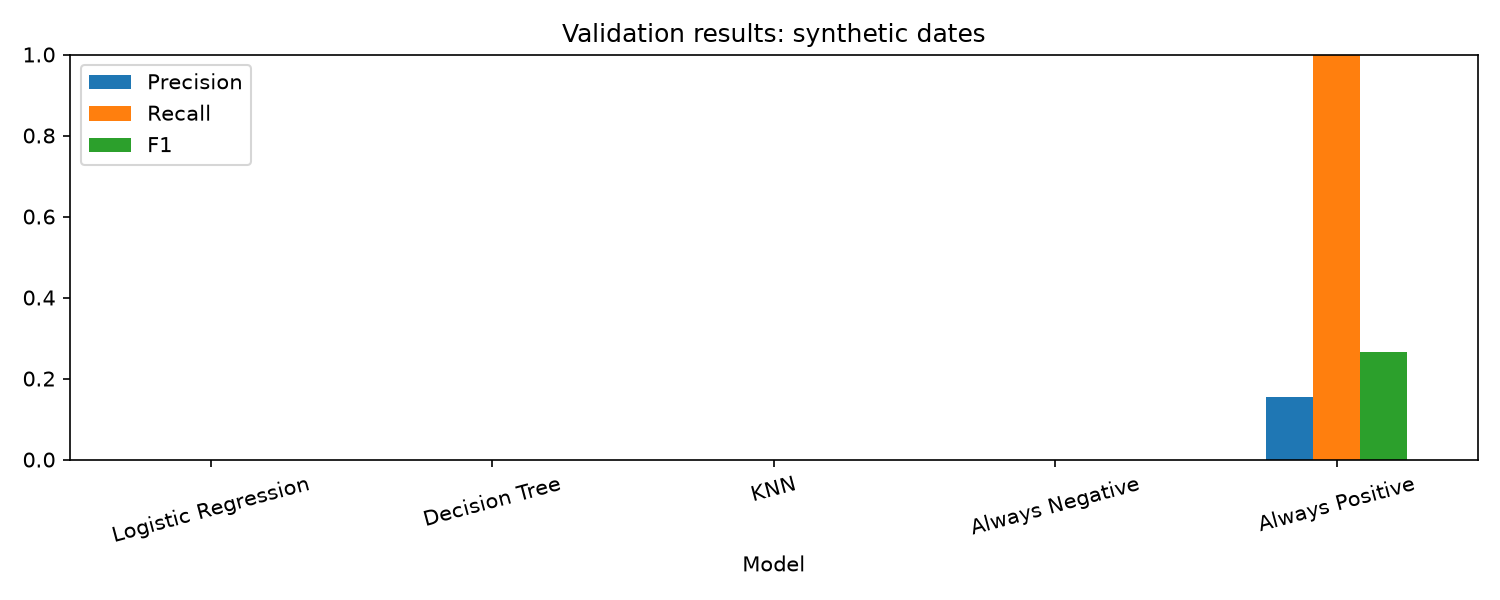

In [15]:
# ===== 4.3 เปรียบเทียบ 3 โมเดล + baseline บน validation =====
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

# class_weight='balanced' ช่วยให้โมเดลสนใจคลาส Positive ที่มีน้อย
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, min_samples_leaf=5,
                                            class_weight='balanced', random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    # baseline: ทาย Negative ทั้งหมด / ทาย Positive ทั้งหมด
    'Always Negative': DummyClassifier(strategy='constant', constant=0),
    'Always Positive': DummyClassifier(strategy='constant', constant=1)
}

# Train ด้วย train แล้ววัดผลบน validation
rows = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    prediction = model.predict(X_validation_scaled)
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_validation, prediction),
                 'Precision': precision_score(y_validation, prediction, zero_division=0),
                 'Recall': recall_score(y_validation, prediction, zero_division=0),
                 'F1': f1_score(y_validation, prediction, zero_division=0)})
validation_results = pd.DataFrame(rows).set_index('Model')
display(validation_results.round(3))

# เลือกโมเดลที่ F1 บน validation สูงสุด (ไม่ดูผล test)
model_names = ['Logistic Regression', 'Decision Tree', 'KNN']
best_name = validation_results.loc[model_names, 'F1'].idxmax()
best_model = models[best_name]
print('Best of the 3 models:', best_name, '(ties use list order)')
print('Better than both baselines:',
      validation_results.loc[best_name, 'F1']
      > validation_results.loc[['Always Negative', 'Always Positive'], 'F1'].max())

# กราฟเปรียบเทียบ Precision / Recall / F1
validation_results[['Precision', 'Recall', 'F1']].plot.bar(
    figsize=(10, 4), ylim=(0, 1), rot=15, title='Validation results: synthetic dates')
plt.tight_layout()
plt.savefig('validation_simple.png', dpi=150)
plt.show()

### 4.4 Test โมเดลที่เลือกแล้ว
คงโมเดลที่ fit ด้วย train เพื่อให้โค้ดตรงไปตรงมา ไม่ refit และไม่เปลี่ยน threshold จากผล test แสดง baseline ด้วย ถ้าโมเดลไม่ดีกว่าให้รายงานตามจริง


              precision    recall  f1-score   support

    Negative       0.80      0.95      0.87        39
    Positive       0.00      0.00      0.00         9

    accuracy                           0.77        48
   macro avg       0.40      0.47      0.44        48
weighted avg       0.65      0.77      0.71        48



<ipython-input-16-f5cb2100b1c1>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.title('Held-out test: synthetic dates'); plt.tight_layout(); plt.savefig('test_simple.png', dpi=150); plt.show()


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.771,0.000,0.0,0.000
Always Negative,0.812,0.000,0.0,0.000
Always Positive,0.188,0.188,1.0,0.316


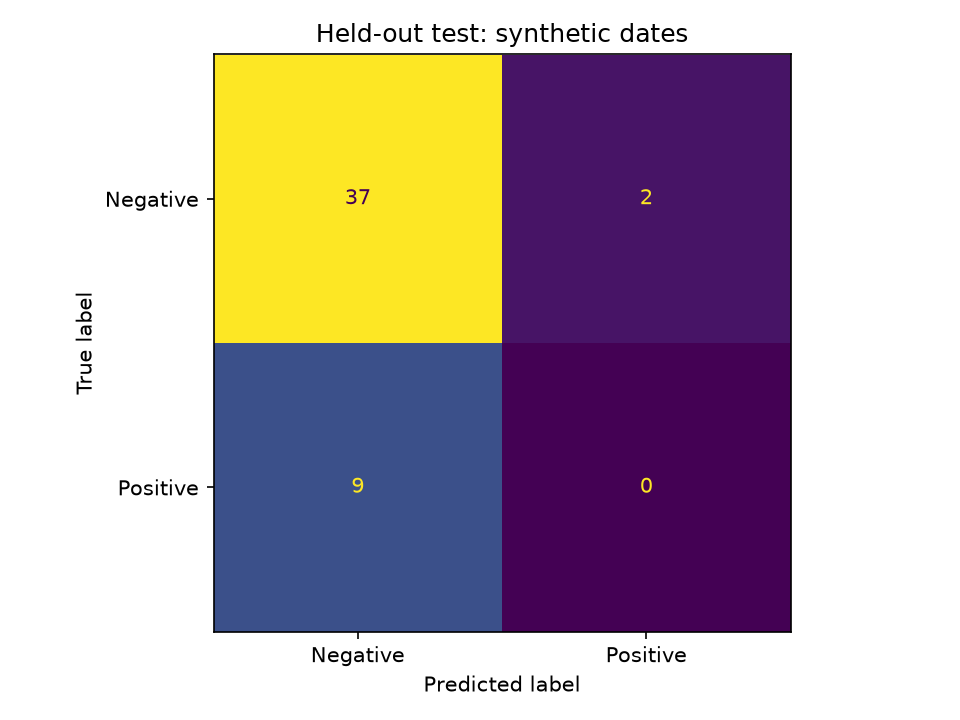

In [16]:
# ===== 4.4 ทดสอบโมเดลที่เลือกบน test (ครั้งเดียว) เทียบกับ baseline =====
test_rows = []
for name in [best_name, 'Always Negative', 'Always Positive']:
    prediction = models[name].predict(X_test_scaled)
    test_rows.append({'Model': name,
                      'Accuracy': accuracy_score(y_test, prediction),
                      'Precision': precision_score(y_test, prediction, zero_division=0),
                      'Recall': recall_score(y_test, prediction, zero_division=0),
                      'F1': f1_score(y_test, prediction, zero_division=0)})
test_results = pd.DataFrame(test_rows).set_index('Model')
display(test_results.round(3))

# รายงานผลละเอียดของโมเดลที่เลือก
test_prediction = best_model.predict(X_test_scaled)
print(classification_report(y_test, test_prediction, labels=[0, 1],
                            target_names=['Negative', 'Positive'], zero_division=0))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, labels=[0, 1],
                                        display_labels=['Negative', 'Positive'], colorbar=False)
plt.title('Held-out test: synthetic dates')
plt.tight_layout()
plt.savefig('test_simple.png', dpi=150)
plt.show()

## 5. เลือกจังหวัดแล้วทำนาย (demo)
แก้ LOCATION แล้วรัน cell นี้ใหม่ ใช้วันจำลอง 2023-01-01, weather 30 วันก่อนหน้า และประวัติปี 2021 เดิม โมเดลยังเป็นโมเดล train เดิม ไม่ได้อัปเดตผลตรวจปี 2022

นี่เป็น demo ของ scenario ไม่ใช่การทำนายวันนี้ ถ้าจังหวัดไม่เคยอยู่ใน train จะหยุด เพราะยังไม่มีผลประเมินสำหรับจังหวัดนั้น คะแนนไม่ใช่ probability ที่สอบเทียบแล้ว และ no risk ไม่รับรองความปลอดภัย


In [17]:
# ===== 5. Demo: เลือกจังหวัดแล้วทำนาย =====
LOCATION = 'Lampang'  # เปลี่ยนเป็นชื่อจังหวัดใน data['Location'].unique()
DEMO_DATE = pd.Timestamp('2023-01-01')

# จังหวัดที่ไม่เคยอยู่ใน train ยังไม่มีผลประเมิน จึงไม่ทำนาย
if LOCATION not in set(train['Location']):
    raise ValueError('Province not present in training data')

# สร้างตัวอย่างใหม่ แล้วเติมอากาศ 30 วัน + ประวัติปี 2021 แบบเดียวกับตอน train
new_sample = pd.DataFrame({'Location': [LOCATION], 'Date': [DEMO_DATE]})
new_sample = new_sample.merge(weather, on=['Location', 'Date'], how='left', validate='many_to_one')
new_sample = new_sample.merge(history_summary, on='Location', how='left', validate='many_to_one')
new_sample['History_count'] = new_sample['History_count'].fillna(0)
assert new_sample[weather_columns].notna().all().all()

# เตรียม feature ด้วยขั้นตอนเดียวกับ train (one-hot → median → scaler)
X_new = (pd.get_dummies(new_sample[features], columns=['Location'], dtype=int)
         .reindex(columns=X_train.columns, fill_value=0))
X_new = X_new.fillna(medians)
X_new_scaled = scaler.transform(X_new)

# ทำนายผล และคะแนนของคลาส Positive (ไม่ใช่ probability ที่สอบเทียบแล้ว)
result = best_model.predict(X_new_scaled)[0]
score = best_model.predict_proba(X_new_scaled)[0, list(best_model.classes_).index(1)]

print('SCENARIO ONLY:', LOCATION, DEMO_DATE.date())
print('Result:', 'have risk' if result == 1 else 'no risk', '| model score:', round(float(score), 3))
print('2021 history samples:', int(new_sample['History_count'].iloc[0]))
print('no risk is not a safety guarantee; synthetic dates and proxy coordinates')

SCENARIO ONLY: Lampang 2023-01-01
Result: no risk | model score: 0.238
2021 history samples: 0
no risk is not a safety guarantee; synthetic dates and proxy coordinates


## 6. Data Interpretation และบันทึกไฟล์
อ่านผลจริงด้านล่างแล้วอธิบายในรายงาน ห้ามสรุปว่าการเพิ่ม weather ทำให้ดีขึ้นโดยไม่มีการเปรียบเทียบบน split เดียวกัน

ข้อจำกัด: วัน/พิกัดสมมติ, ประวัติปี 2021 มีไม่ครบทุกจังหวัดและไม่อัปเดต, ข้อมูลน้อย/คลาสไม่สมดุล, หน่วยสารและกฎ label ยังต้องยืนยัน, ไม่รู้รหัสล็อต และยังไม่จำลองเวลาที่ NASA เผยแพร่ข้อมูลจริง

ไฟล์ส่งงาน: เติมชื่อ/รหัส/หน้าที่สมาชิกทุกคนในบรรทัดแรก แล้วเปลี่ยนชื่อ notebook นี้เป็น Sectionxxxxxx_Gyy_ชื่อกลุ่ม.ipynb ทำ PDF ชื่อเดียวกันเรียงตามหัวข้อรายวิชา พร้อมภาพจากการรันจริง รวม ipynb + PDF เป็น ZIP ตาม instruction

Data Collection ทั้ง Excel และ NASA API อยู่ใน notebook นี้ครบแล้ว ไฟล์ Excel/ภาพที่สร้างเป็นวัสดุประกอบรายงาน ดาวน์โหลดเพิ่มเติมได้จาก Files ด้านซ้ายของ Colab


In [18]:
# ===== 6. บันทึกผลทั้งหมดเป็น Excel สำหรับประกอบรายงาน =====
with pd.ExcelWriter('Rice_Project_Results.xlsx', engine='openpyxl') as writer:
    quality.to_excel(writer, sheet_name='Cleansing', index=False)
    history_summary.to_excel(writer, sheet_name='History_2021', index=False)
    data.to_excel(writer, sheet_name='Merged_2022', index=False)
    validation_results.to_excel(writer, sheet_name='Validation')
    test_results.to_excel(writer, sheet_name='Test')
    label_review[['Sample ID', 'Location', 'Result (positive/negative)']].to_excel(
        writer, sheet_name='Label_review', index=False)
    excluded_years.to_excel(writer, sheet_name='Excluded_years', index=False)
    excluded_early.to_excel(writer, sheet_name='Excluded_early_January', index=False)
    purged.to_excel(writer, sheet_name='Purged_before_split', index=False)

# สรุปผลสั้น ๆ แล้วบันทึกเป็น results_summary.txt
summary = (f'SCENARIO ONLY | history={len(history)}, modeling={len(data)}\n'
           f'train={len(train)}, validation={len(validation)}, test={len(test)}, purged={len(purged)}\n'
           f'Selected: {best_name} | validation F1={validation_results.loc[best_name, "F1"]:.3f}\n'
           f'Test recall={test_results.loc[best_name, "Recall"]:.3f}, F1={test_results.loc[best_name, "F1"]:.3f}\n'
           'Mock dates / proxy coordinates: not a field validation.')
print(summary)
with open('results_summary.txt', 'w') as file:
    file.write(summary)

# ดาวน์โหลดไฟล์ผลลัพธ์ (เฉพาะใน Colab)
if IN_COLAB:
    files.download('Rice_Project_Results.xlsx')

SCENARIO ONLY | history=171, modeling=268
train=153, validation=52, test=48, purged=15
Selected: Logistic Regression | validation F1=0.000
Test recall=0.000, F1=0.000
Mock dates / proxy coordinates: not a field validation.
